# TD OpenCV

Corrigé : chaque exercice est résolu dans la cellule de code qui suit sa consigne. Les images produites sont enregistrées dans `resultats/`. Documentation détaillée : `README.md`.

In [1]:
# Imports communs à tous les exercices.
# Le notebook s'exécute depuis le dossier TD/ (les chemins des images sont relatifs à ce dossier).
# Attention : OpenCV >= 4.8 et < 5 (en OpenCV 5.0, cv2.CascadeClassifier n'est plus dans le paquet principal).
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

%config InlineBackend.figure_format = "jpeg"  # figures en JPEG : notebook plus léger

print("OpenCV", cv2.__version__)
os.makedirs("resultats", exist_ok=True)


def afficher(images, titres=None, colonnes=None, taille=4.5):
    """Affiche une ou plusieurs images (BGR ou niveaux de gris) avec matplotlib."""
    if not isinstance(images, (list, tuple)):
        images = [images]
    titres = titres or [""] * len(images)
    colonnes = colonnes or len(images)
    lignes = (len(images) + colonnes - 1) // colonnes
    fig, axes = plt.subplots(lignes, colonnes, figsize=(taille * colonnes * 1.4, taille * lignes), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, img, titre in zip(axes.ravel(), images, titres):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray")
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(titre)
    plt.tight_layout()
    plt.show()

OpenCV 4.14.0


## Exercice 1 : transformer une zone de pixel

Avec OpenCV, écrire un code qui permet de choisir une zone d'une image et la transforme en pixels noirs.

Zone noircie : x=460, y=235, w=275, h=225


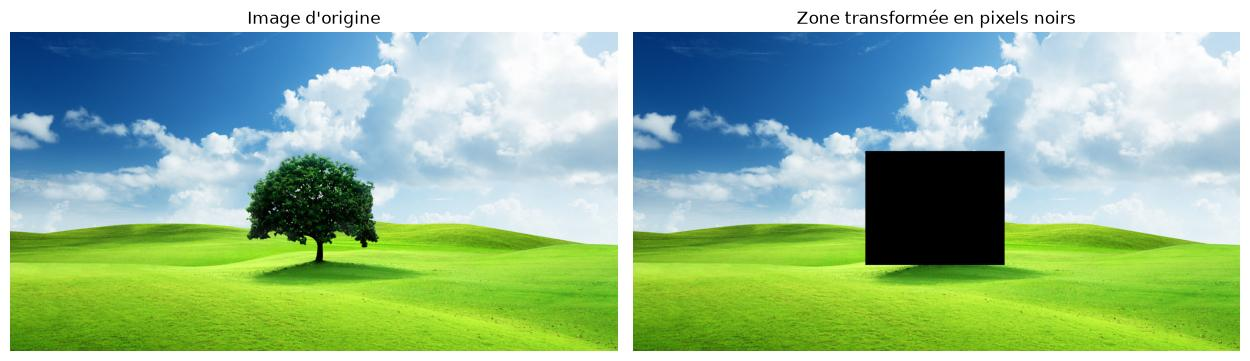

In [2]:
def noircir_zone(img, x, y, w, h):
    """Renvoie une copie de l'image où le rectangle (x, y, w, h) est mis en noir.
    Le rectangle est rogné aux bords de l'image pour éviter les indices hors limites."""
    sortie = img.copy()
    H, W = sortie.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(W, x + w), min(H, y + h)
    sortie[y1:y2, x1:x2] = 0  # une image OpenCV est un tableau numpy [ligne, colonne, canal]
    return sortie


img = cv2.imread("Exercice 1/sample.jpg")

# INTERACTIF = True : on dessine la zone à la souris (fenêtre OpenCV, ne marche pas sur Colab),
# puis Entrée/Espace pour valider. Sinon on utilise une zone fixe (l'arbre).
INTERACTIF = False
if INTERACTIF:
    x, y, w, h = cv2.selectROI("Choisir la zone puis Entree", img, showCrosshair=True)
    cv2.destroyAllWindows()
else:
    x, y, w, h = 460, 235, 275, 225

resultat = noircir_zone(img, x, y, w, h)
cv2.imwrite("resultats/ex1_zone_noire.jpg", resultat)
print(f"Zone noircie : x={x}, y={y}, w={w}, h={h}")
afficher([img, resultat], ["Image d'origine", "Zone transformée en pixels noirs"])

## Exercice 2 : vérifier des annotations

Labelliser 5 images sur Makesense.ai puis vérifier les annotations en recodant la construction des bounding box grâce à OpenCV.

*Vous pouvez le faire sur les images ./foot_{k}.jpg (minimum 3 objets annotés par image). 3 classes : ballon, joueur, arbitre.*

**Annotations.** Les boîtes ont été faites au format d'export **YOLO** de Makesense.ai
(`Actions > Export annotations > YOLO`) et sont rangées dans `Exercice 2/annotations/` :

* `labels.txt` : une classe par ligne, l'indice de la ligne est l'identifiant (`0 ballon`, `1 joueur`, `2 arbitre`) ;
* `foot_k.txt` : une ligne par objet, `classe x_centre y_centre largeur hauteur`, valeurs **normalisées** entre 0 et 1.

Pour vérifier, on reconstruit les boîtes en pixels :
`x1 = (xc - w/2) * W`, `y1 = (yc - h/2) * H`, `x2 = (xc + w/2) * W`, `y2 = (yc + h/2) * H`,
puis on les dessine avec `cv2.rectangle`. Les gardiens sont annotés `joueur` ; l'`arbitre` visible est l'arbitre assistant (tenue fluo) sur foot_1 et foot_2.

foot_1 : 8 objets {'ballon': 1, 'joueur': 6, 'arbitre': 1}
foot_2 : 6 objets {'ballon': 1, 'joueur': 4, 'arbitre': 1}
foot_3 : 5 objets {'ballon': 1, 'joueur': 4, 'arbitre': 0}
foot_4 : 5 objets {'ballon': 1, 'joueur': 4, 'arbitre': 0}
foot_5 : 5 objets {'ballon': 1, 'joueur': 4, 'arbitre': 0}


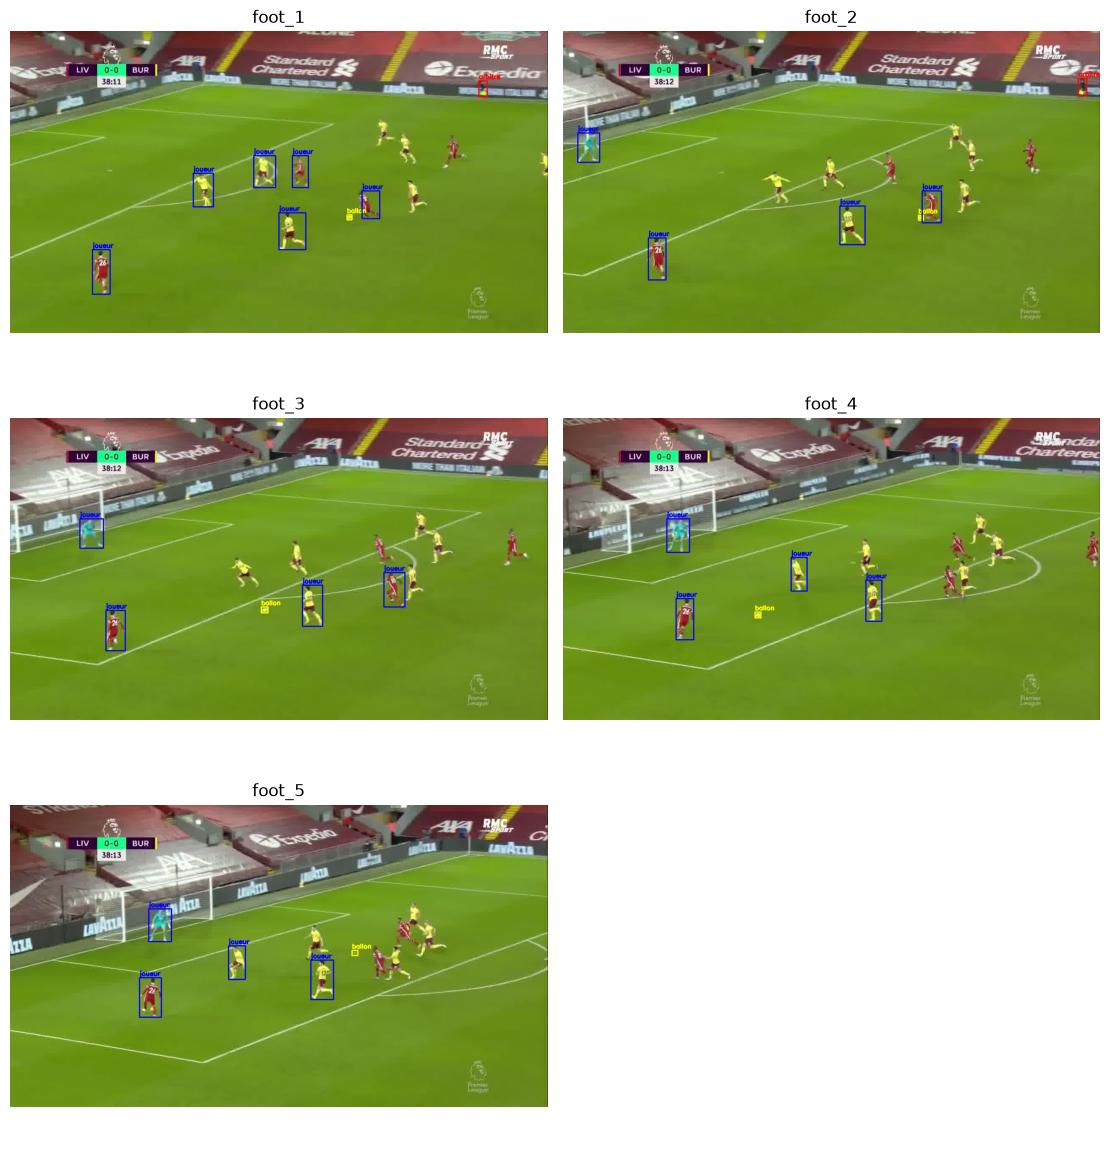

In [3]:
DOSSIER = "Exercice 2"
CLASSES = open(f"{DOSSIER}/annotations/labels.txt").read().split()
COULEURS = {"ballon": (0, 255, 255), "joueur": (255, 0, 0), "arbitre": (0, 0, 255)}  # BGR


def lire_annotations_yolo(chemin, W, H):
    """Lit un fichier YOLO et renvoie une liste (classe, x1, y1, x2, y2) en pixels."""
    boites = []
    for ligne in open(chemin):
        if not ligne.strip():
            continue
        c, xc, yc, w, h = ligne.split()
        xc, yc, w, h = float(xc) * W, float(yc) * H, float(w) * W, float(h) * H
        boites.append((CLASSES[int(c)], round(xc - w / 2), round(yc - h / 2), round(xc + w / 2), round(yc + h / 2)))
    return boites


def dessiner_boites(img, boites):
    sortie = img.copy()
    for classe, x1, y1, x2, y2 in boites:
        couleur = COULEURS[classe]
        cv2.rectangle(sortie, (x1, y1), (x2, y2), couleur, 2)
        cv2.putText(sortie, classe, (x1, max(12, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, couleur, 2)
    return sortie


images, titres = [], []
for k in range(1, 6):
    img = cv2.imread(f"{DOSSIER}/foot_{k}.jpg")
    H, W = img.shape[:2]
    boites = lire_annotations_yolo(f"{DOSSIER}/annotations/foot_{k}.txt", W, H)
    # contrôles automatiques : au moins 3 objets, boîtes non vides et dans l'image
    assert len(boites) >= 3, f"foot_{k} : moins de 3 objets"
    for _, x1, y1, x2, y2 in boites:
        assert 0 <= x1 < x2 <= W and 0 <= y1 < y2 <= H, f"foot_{k} : boîte invalide {(x1, y1, x2, y2)}"
    comptes = {c: sum(b[0] == c for b in boites) for c in CLASSES}
    print(f"foot_{k} : {len(boites)} objets {comptes}")
    annotee = dessiner_boites(img, boites)
    cv2.imwrite(f"resultats/ex2_foot_{k}_annote.jpg", annotee)
    images.append(annotee)
    titres.append(f"foot_{k}")

afficher(images, titres, colonnes=2, taille=4)

## Exercice 3 : détection de contours

Compter les bulles à l'intérieur de l'image bubble.png. Vous utiliserez la fonction find_contours d'opencv pour le faire.

*Une bulle étant définie comme un contour qui contient un autre contour à l'intérieur.*

40 contours trouvés, dont 8 bulles


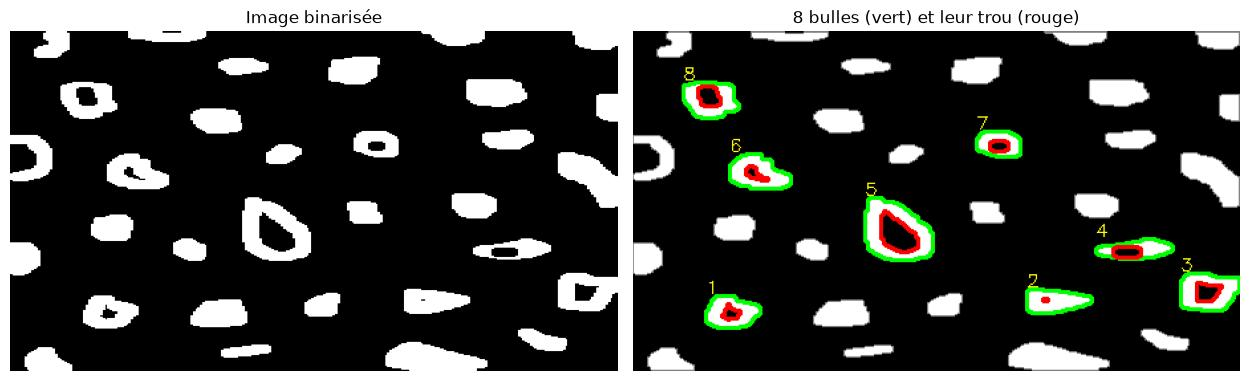

In [4]:
img = cv2.imread("Exercice 3/bubble.png")
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, binaire = cv2.threshold(gris, 127, 255, cv2.THRESH_BINARY)  # formes blanches sur fond noir

# RETR_TREE renvoie la hiérarchie complète des contours :
# hierarchie[i] = [suivant, précédent, premier_enfant, parent]
contours, hierarchie = cv2.findContours(binaire, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
hierarchie = hierarchie[0]

# Une bulle = un contour qui contient un autre contour, donc qui a un enfant (premier_enfant != -1).
bulles = [i for i in range(len(contours)) if hierarchie[i][2] != -1]
print(f"{len(contours)} contours trouvés, dont {len(bulles)} bulles")

sortie = img.copy()
cv2.drawContours(sortie, contours, -1, (128, 128, 128), 1)  # tous les contours en gris
for n, i in enumerate(bulles, 1):
    cv2.drawContours(sortie, contours, i, (0, 255, 0), 2)  # bulle (contour extérieur) en vert
    cv2.drawContours(sortie, contours, hierarchie[i][2], (0, 0, 255), 2)  # son contour intérieur en rouge
    x, y, w, h = cv2.boundingRect(contours[i])
    cv2.putText(sortie, str(n), (x, max(10, y - 2)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 255), 1)
cv2.imwrite("resultats/ex3_bulles.png", sortie)
afficher([binaire, sortie], ["Image binarisée", f"{len(bulles)} bulles (vert) et leur trou (rouge)"])

## Exercice 4 : détection de visages

1 - Coder un détécteur de visage avec OpenCV en utilisant la fonction cv2.CascadeClassifier et la méthode Haar.

Cascade seule : 2 détection(s) : [(574, 592, 96, 96), (724, 201, 164, 164)]
  minNeighbors=0 -> 92 détection(s)
  minNeighbors=1 -> 4 détection(s)
  minNeighbors=3 -> 2 détection(s)
  minNeighbors=5 -> 2 détection(s)
  minNeighbors=8 -> 2 détection(s)
  minNeighbors=10 -> 1 détection(s)
Avec vérification des yeux : 1 visage(s) : [(724, 201, 164, 164)]


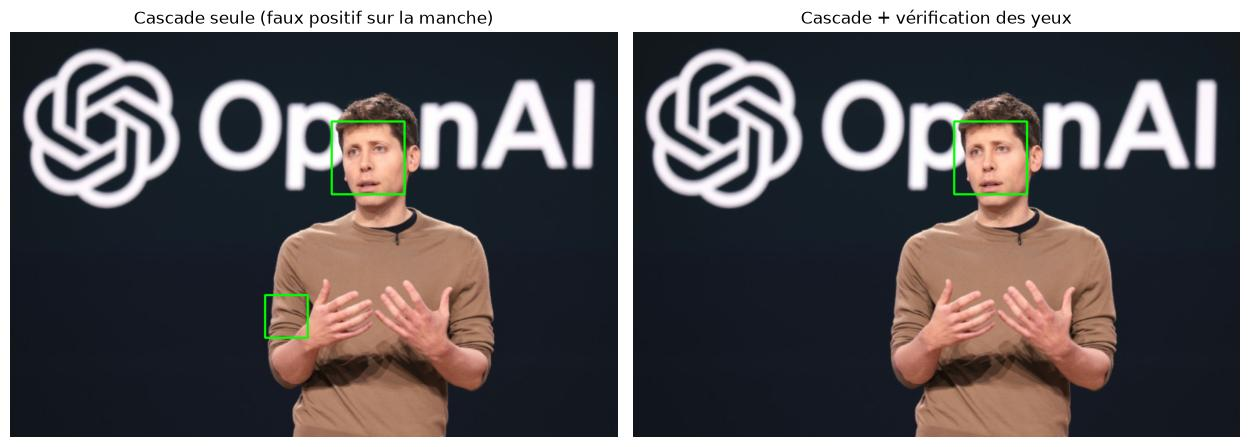

In [5]:
# Classifieur en cascade de Haar pré-entraîné (Viola & Jones), livré avec OpenCV.
cascade_visage = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
cascade_yeux = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_eye.xml")
assert not cascade_visage.empty() and not cascade_yeux.empty(), "fichier de cascade introuvable"


def detecter_visages(img_bgr, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40), verifier_yeux=False):
    """Renvoie la liste des visages (x, y, w, h).
    - scaleFactor : facteur de réduction de l'image entre deux échelles de la pyramide ;
    - minNeighbors : nombre de détections voisines nécessaires pour garder un visage
      (plus grand = moins de faux positifs, mais risque de rater des visages) ;
    - verifier_yeux : ne garde que les visages où une 2e cascade trouve au moins un œil
      dans la moitié haute (élimine les faux positifs sur des textures)."""
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)  # les features de Haar travaillent en niveaux de gris
    gris = cv2.equalizeHist(gris)  # égalisation : moins sensible à l'éclairage
    visages = cascade_visage.detectMultiScale(gris, scaleFactor=scaleFactor, minNeighbors=minNeighbors, minSize=minSize)
    if verifier_yeux:
        visages = [(x, y, w, h) for x, y, w, h in visages
                   if len(cascade_yeux.detectMultiScale(gris[y:y + 2 * h // 3, x:x + w], 1.1, 5)) > 0]
    return visages


def dessiner_visages(img_bgr, visages):
    sortie = img_bgr.copy()
    for x, y, w, h in visages:
        cv2.rectangle(sortie, (x, y), (x + w, y + h), (0, 255, 0), 3)
    return sortie


img = cv2.imread("Exercice 4/sam_altman.jpg")
brut = detecter_visages(img)
print(f"Cascade seule : {len(brut)} détection(s) :", [tuple(int(v) for v in f) for f in brut])

# Influence de minNeighbors sur le nombre de détections
for mn in [0, 1, 3, 5, 8, 10]:
    print(f"  minNeighbors={mn} -> {len(detecter_visages(img, minNeighbors=mn))} détection(s)")

visages = detecter_visages(img, verifier_yeux=True)
print(f"Avec vérification des yeux : {len(visages)} visage(s) :", [tuple(int(v) for v in f) for f in visages])

cv2.imwrite("resultats/ex4_visage_brut.jpg", dessiner_visages(img, brut))
resultat = dessiner_visages(img, visages)
cv2.imwrite("resultats/ex4_visage.jpg", resultat)
afficher([dessiner_visages(img, brut), resultat],
         ["Cascade seule (faux positif sur la manche)", "Cascade + vérification des yeux"])

2 - Appliquer cette fonction sur les images de votre webcam

In [6]:
import time


def webcam_visages(camera=0, minNeighbors=5):
    """Détection de visages en direct sur la webcam. Touche q (ou Échap) pour quitter.
    Utilise une fenêtre OpenCV : à lancer en local (pas sur Colab, où cv2.imshow n'existe pas)."""
    cap = cv2.VideoCapture(camera)
    if not cap.isOpened():
        print("Webcam introuvable")
        return
    t_prec = time.time()
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frame = cv2.flip(frame, 1)  # effet miroir, plus naturel
            visages = detecter_visages(frame, minNeighbors=minNeighbors)
            frame = dessiner_visages(frame, visages)
            t = time.time()
            fps = 1 / max(t - t_prec, 1e-6)
            t_prec = t
            cv2.putText(frame, f"{len(visages)} visage(s) - {fps:.0f} FPS", (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
            cv2.imshow("Visages (q pour quitter)", frame)
            if cv2.waitKey(1) & 0xFF in (ord("q"), 27):
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()


# Mettre True pour lancer (désactivé par défaut pour que le notebook s'exécute de bout en bout sans webcam).
# Version script : python "Exercice 4/webcam_visages.py"
LANCER_WEBCAM = False
if LANCER_WEBCAM:
    webcam_visages()

## Exercice 5 : template matching

Appliquer l'opération de template matching avec le template : /template.jpg sur l'image /ref_image.jpg

Vous utiliserez la fonction cv2.matchTemplate d'OpenCV.

Meilleur match en (x=113, y=123), score = 0.991
  TM_SQDIFF         -> (113, 123)
  TM_SQDIFF_NORMED  -> (113, 123)
  TM_CCORR          -> (113, 123)
  TM_CCORR_NORMED   -> (113, 123)
  TM_CCOEFF         -> (113, 123)
  TM_CCOEFF_NORMED  -> (113, 123)


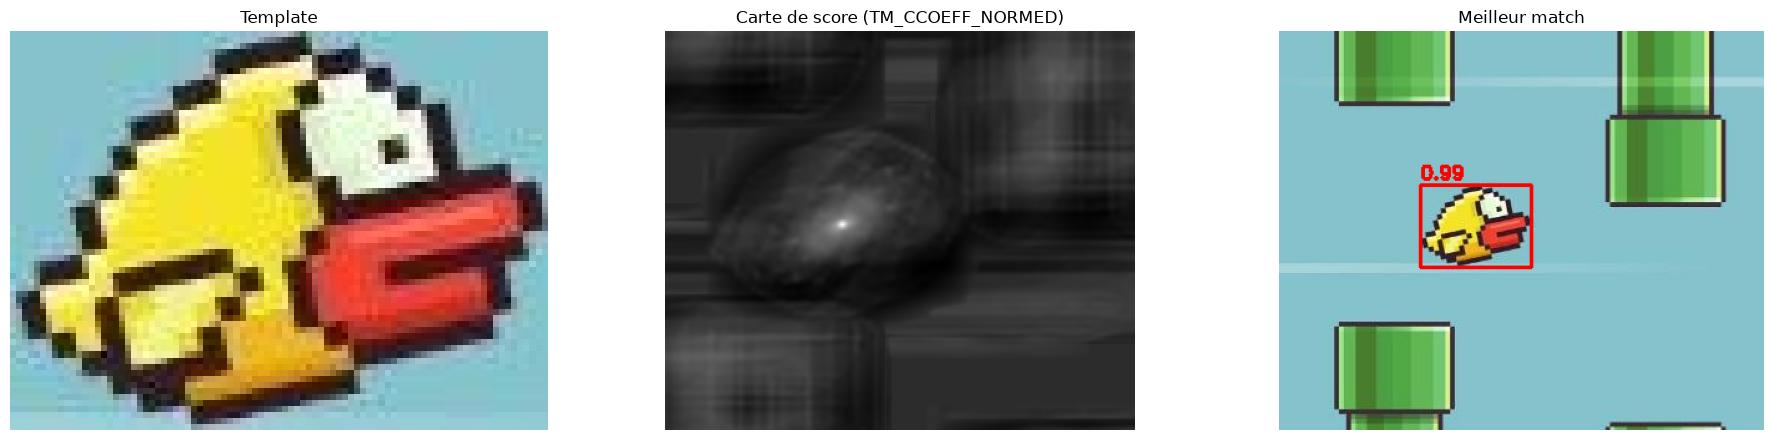

In [7]:
img = cv2.imread("Exercice 5/ref_image.jpg")
template = cv2.imread("Exercice 5/template.jpg")
h, w = template.shape[:2]

# matchTemplate fait glisser le template sur l'image et calcule un score à chaque position.
# TM_CCOEFF_NORMED : corrélation normalisée entre -1 et 1, le meilleur match est le MAXIMUM.
carte = cv2.matchTemplate(img, template, cv2.TM_CCOEFF_NORMED)
_, score_max, _, (x, y) = cv2.minMaxLoc(carte)
print(f"Meilleur match en (x={x}, y={y}), score = {score_max:.3f}")

# Comparaison des 6 méthodes : pour SQDIFF le meilleur match est le MINIMUM (c'est une distance).
for nom in ["TM_SQDIFF", "TM_SQDIFF_NORMED", "TM_CCORR", "TM_CCORR_NORMED", "TM_CCOEFF", "TM_CCOEFF_NORMED"]:
    c = cv2.matchTemplate(img, template, getattr(cv2, nom))
    vmin, vmax, pmin, pmax = cv2.minMaxLoc(c)
    print(f"  {nom:17s} -> {pmin if 'SQDIFF' in nom else pmax}")

resultat = img.copy()
cv2.rectangle(resultat, (x, y), (x + w, y + h), (0, 0, 255), 2)
cv2.putText(resultat, f"{score_max:.2f}", (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
cv2.imwrite("resultats/ex5_template_matching.jpg", resultat)
carte_affichee = cv2.normalize(carte, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
afficher([template, carte_affichee, resultat], ["Template", "Carte de score (TM_CCOEFF_NORMED)", "Meilleur match"])

## Exercice 6 : image stitching

A partir de 2 images : droite.png et gauche.png, écrire un code en OpenCV qui permettra de recoller les 2 images au bon endroit.

* Etape 1 : trouver les features importantes sur l'image
* Etape 2 : trouver les matchs entre les 2 images (points similaires)
* Etape 3 : trouver un coefficient de translation pour l'image de droite
* Etape 4 : recoller l'image finale

Étape 1 : 2799 points sur gauche, 1758 sur droite


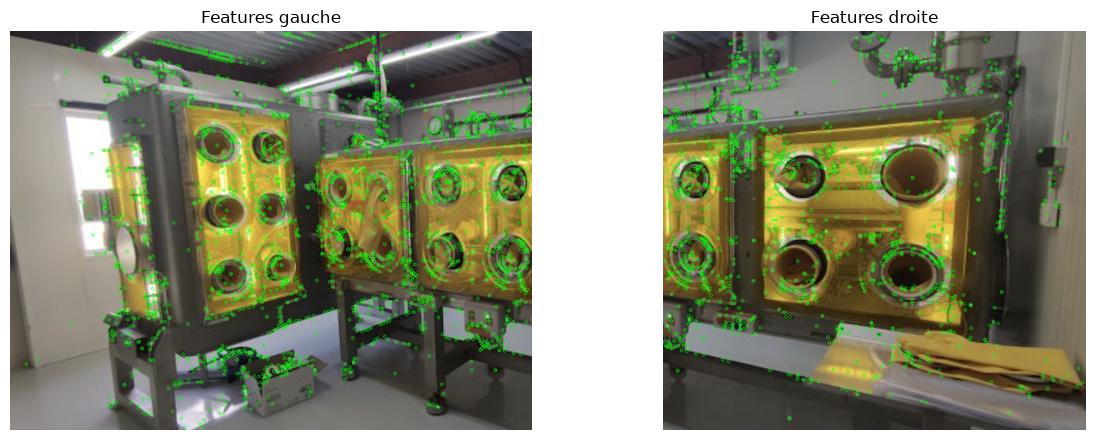

In [8]:
gauche = cv2.imread("Exercice 6/gauche.png")
droite = cv2.imread("Exercice 6/droite.png")

# Étape 1 : points d'intérêt + descripteurs SIFT (invariants à l'échelle et à la rotation)
sift = cv2.SIFT_create()
kp_g, des_g = sift.detectAndCompute(cv2.cvtColor(gauche, cv2.COLOR_BGR2GRAY), None)
kp_d, des_d = sift.detectAndCompute(cv2.cvtColor(droite, cv2.COLOR_BGR2GRAY), None)
print(f"Étape 1 : {len(kp_g)} points sur gauche, {len(kp_d)} sur droite")
afficher([cv2.drawKeypoints(gauche, kp_g, None, color=(0, 255, 0)),
          cv2.drawKeypoints(droite, kp_d, None, color=(0, 255, 0))], ["Features gauche", "Features droite"])

Étape 2 : 1758 matchs bruts, 357 conservés après le test du ratio


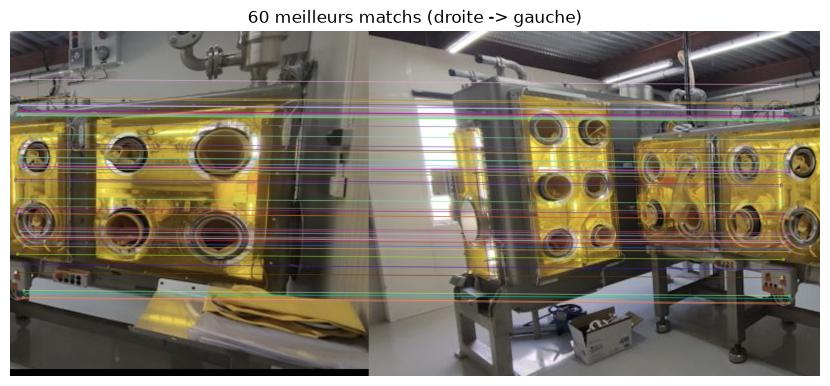

In [9]:
# Étape 2 : appariement. Pour chaque descripteur de droite on cherche ses 2 plus proches voisins dans gauche,
# et on garde le match seulement s'il est nettement meilleur que le 2e (test du ratio de Lowe).
matcher = cv2.BFMatcher(cv2.NORM_L2)
paires = matcher.knnMatch(des_d, des_g, k=2)
bons = [m for m, n in paires if m.distance < 0.75 * n.distance]
print(f"Étape 2 : {len(paires)} matchs bruts, {len(bons)} conservés après le test du ratio")

img_matchs = cv2.drawMatches(droite, kp_d, gauche, kp_g, sorted(bons, key=lambda m: m.distance)[:60], None,
                             flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
cv2.imwrite("resultats/ex6_matchs.jpg", img_matchs)
afficher(img_matchs, ["60 meilleurs matchs (droite -> gauche)"], taille=6)

Étape 3 : translation (dx, dy) = (1056, 14) ; 342/357 matchs à moins de 10 px de cette translation
Contrôle par similitude : échelle=0.9999, angle=0.004°, t=(1056.0, 14.0)


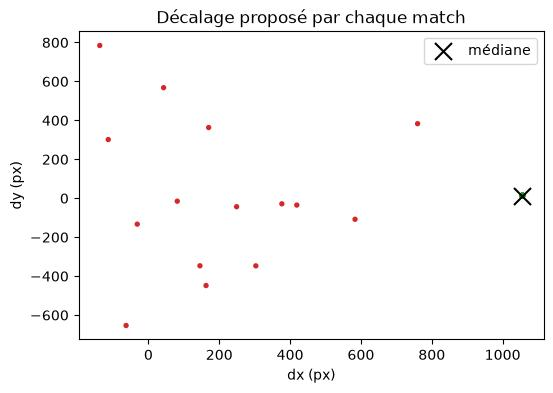

In [10]:
# Étape 3 : coefficient de translation. Pour chaque match, le décalage (dx, dy) = point_gauche - point_droite
# dit où placer l'origine de l'image de droite dans le repère de l'image de gauche.
# On prend la MÉDIANE : robuste aux faux matchs restants (contrairement à la moyenne).
pts_d = np.float32([kp_d[m.queryIdx].pt for m in bons])
pts_g = np.float32([kp_g[m.trainIdx].pt for m in bons])
decalages = pts_g - pts_d
dx, dy = np.median(decalages, axis=0)
coherents = np.linalg.norm(decalages - (dx, dy), axis=1) < 10
print(f"Étape 3 : translation (dx, dy) = ({dx:.0f}, {dy:.0f}) ; "
      f"{coherents.sum()}/{len(bons)} matchs à moins de 10 px de cette translation")

# Vérification : un modèle plus riche (similitude = rotation + échelle + translation, estimé par RANSAC)
# doit retrouver une échelle ~1 et un angle ~0 si une translation suffit.
A, _ = cv2.estimateAffinePartial2D(pts_d, pts_g, method=cv2.RANSAC, ransacReprojThreshold=5)
echelle = np.hypot(A[0, 0], A[1, 0])
angle = np.degrees(np.arctan2(A[1, 0], A[0, 0]))
print(f"Contrôle par similitude : échelle={echelle:.4f}, angle={angle:.3f}°, t=({A[0, 2]:.1f}, {A[1, 2]:.1f})")

plt.figure(figsize=(6, 4))
plt.scatter(decalages[:, 0], decalages[:, 1], s=8, c=np.where(coherents, "tab:green", "tab:red"))
plt.scatter([dx], [dy], marker="x", s=150, c="k", label="médiane")
plt.xlabel("dx (px)"); plt.ylabel("dy (px)"); plt.title("Décalage proposé par chaque match"); plt.legend()
plt.show()

Étape 4 : panorama de 1986 x 894 px (recouvrement de 114 px)


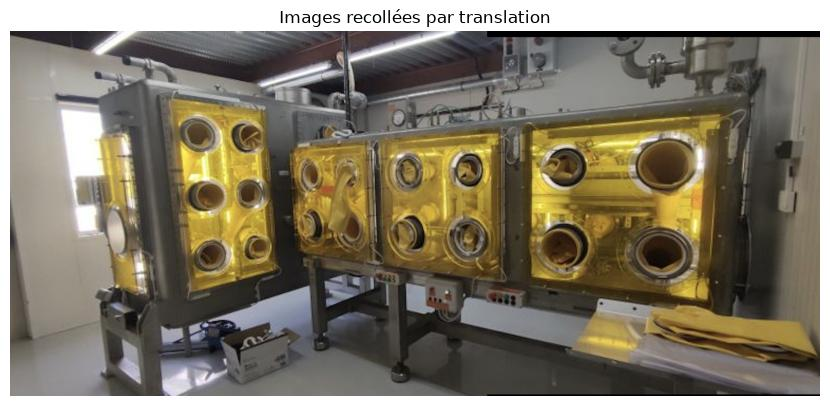

In [11]:
# Étape 4 : recollage. On crée une toile assez grande pour les deux images, on pose gauche,
# puis droite décalée de (dx, dy). Les décalages négatifs sont gérés par un offset sur la toile.
dx, dy = int(round(dx)), int(round(dy))
hg, wg = gauche.shape[:2]
hd, wd = droite.shape[:2]
ox, oy = max(0, -dx), max(0, -dy)  # position de gauche sur la toile
largeur = max(ox + wg, ox + dx + wd)
hauteur = max(oy + hg, oy + dy + hd)

panorama = np.zeros((hauteur, largeur, 3), np.uint8)
occupe = np.zeros((hauteur, largeur), bool)  # pixels couverts par l'image de gauche
panorama[oy:oy + hg, ox:ox + wg] = gauche
occupe[oy:oy + hg, ox:ox + wg] = True

# Dans la bande de recouvrement, fondu linéaire gauche -> droite pour cacher la couture.
recouvrement = ox + wg - (ox + dx)
alpha = np.clip(np.arange(wd) / max(1, recouvrement), 0, 1)[None, :, None]  # 0 au bord gauche de droite, 1 après la bande
zone = (slice(oy + dy, oy + dy + hd), slice(ox + dx, ox + dx + wd))
melange = np.where(occupe[zone][..., None], (1 - alpha) * panorama[zone] + alpha * droite, droite)
panorama[zone] = melange.astype(np.uint8)

cv2.imwrite("resultats/ex6_panorama.jpg", panorama)
print(f"Étape 4 : panorama de {largeur} x {hauteur} px (recouvrement de {recouvrement} px)")
afficher(panorama, ["Images recollées par translation"], taille=6)